**The word2vec models and approximate training methods**:
let’s walk through their implementations. Specifically, we will take the skipgram
model and negative sampling as an example. In this
section, we begin with the dataset for pretraining the word embedding model: the original
format of the data will be transformed into minibatches that can be iterated over during
training.

In [1]:
!pip install -q --no-deps d2l==1.0.3

In [2]:
import collections
import math
import os
import random
import torch
from d2l import torch as d2l

**Penn Tree Bank (PTB)230 dataset**:
This corpus is sampled from Wall
Street Journal articles, split into training, validation, and test sets. In the original format,
each line of the text file represents a sentence of words that are separated by spaces. Here
we treat each word as a token.

In [32]:
#save
d2l.DATA_HUB['ptb'] = (d2l.DATA_URL + 'ptb.zip',
'319d85e578af0cdc590547f26231e4e31cdf1e42')
#save
def read_ptb():
    """Load the PTB dataset into a list of text lines."""
    data_dir = d2l.download_extract('ptb')
    # Read the training set
    with open(os.path.join(data_dir, 'ptb.train.txt')) as f:
        raw_text = f.read()
    return [line.split() for line in raw_text.split('\n')]
sentences = read_ptb()
f'# sentences: {len(sentences)}'

'# sentences: 42069'

After reading the training set, we build a vocabulary for the corpus, where any word that
appears less than 10 times is replaced by the “<unk>” token. Note that the original dataset
also contains “<unk>” tokens that represent rare (unknown) words.

In [4]:
vocab = d2l.Vocab(sentences, min_freq=10)
f'vocab size: {len(vocab)}'

'vocab size: 6719'

**Subsampling**:
Text data typically have high-frequency words such as “the”, “a”, and “in”: they may even
occur billions of times in very large corpora. However, these words often co-occur with
many different words in context windows, providing little useful signals. For instance,
consider the word “chip” in a context window: intuitively its co-occurrence with a lowfrequency
word “intel” is more useful in training than the co-occurrence with a highfrequency
word “a”. Moreover, training with vast amounts of (high-frequency) words is
slow. Thus, when training word embedding models, high-frequency words can be subsampled
(Mikolov et al., 2013). Specifically, each indexed word 𝑤𝑖 in the dataset will be
discarded with probability 𝑃(𝑤𝑖)= F(f(wi)). where 𝑓(𝑤𝑖) is the ratio of the number of words 𝑤𝑖 to the total number of words in the
dataset, and the constant 𝑡 is a hyperparameter (10-4 in the experiment). We can see that only when the relative frequency 𝑓(𝑤𝑖) > 𝑡 can the (high-frequency) word 𝑤𝑖 be discarded,
and the higher the relative frequency of the word, the greater the probability of being discarded.

In [5]:
#save
def subsample(sentences, vocab):
  """Subsample high-frequency words."""
  # Exclude unknown tokens ('<unk>')
  sentences = [[token for token in line if vocab[token] != vocab.unk]
  for line in sentences]
  counter = collections.Counter([
  token for line in sentences for token in line])
  num_tokens = sum(counter.values())
  # Return True if `token` is kept during subsampling
  def keep(token):
    return(random.uniform(0, 1) <
      math.sqrt(1e-4 / counter[token] * num_tokens))
  return ([[token for token in line if keep(token)] for line in sentences],
          counter)
subsampled, counter = subsample(sentences, vocab)

The following code snippet plots the histogram of the number of tokens per sentence before
and after subsampling. As expected, subsampling significantly shortens sentences by
dropping high-frequency words, which will lead to training speedup.

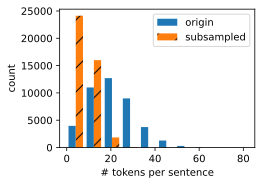

In [36]:
d2l.show_list_len_pair_hist(['origin', 'subsampled'], '# tokens per sentence',
'count', sentences, subsampled);

For individual tokens, the sampling rate of the high-frequency word “the” is less than
1/20.

In [37]:
def compare_counts(token):
  return (f'# of "{token}": '
  f'before={sum([l.count(token) for l in sentences])}, '
  f'after={sum([l.count(token) for l in subsampled])}')
compare_counts('the')

'# of "the": before=50770, after=2013'

In contrast, low-frequency words “join” are completely kept.

In [8]:
compare_counts('join')

'# of "join": before=45, after=45'

After subsampling, we map tokens to their indices for the corpus.

In [45]:
corpus = [vocab[line] for line in subsampled]
corpus[:2]

[[], [3228, 1773, 4060]]

**Extracting Center Words and Context Words**:
The following get_centers_and_contexts function extracts all the center words and their
context words from corpus. It uniformly samples an integer between 1 and max_window_size
at random as the context window size. For any center word, those words whose distance
from it does not exceed the sampled context window size are its context words.

In [46]:
#save
def get_centers_and_contexts(corpus, max_window_size):
  """Return center words and context words in skip-gram."""
  centers, contexts = [], []
  for line in corpus:
    # To form a "center word--context word" pair, each sentence needs to
    # have at least 2 words
    if len(line) < 2:
      continue
    centers += line
    for i in range(len(line)): # Context window centered at `i`
         window_size = random.randint(1, max_window_size)
         indices = list(range(max(0, i - window_size),
         min(len(line), i + 1 + window_size)))
          # Exclude the center word from the context words
         indices.remove(i)
         contexts.append([line[idx] for idx in indices])
  return centers, contexts

Next, we create an artificial dataset containing two sentences of 7 and 3 words, respectively.
Let the maximum context window size be 2 and print all the center words and their context
words.

In [47]:
tiny_dataset = [list(range(7)), list(range(7, 10))]
print('dataset', tiny_dataset)
for center, context in zip(*get_centers_and_contexts(tiny_dataset, 2)):
    print('center', center, 'has contexts', context)

dataset [[0, 1, 2, 3, 4, 5, 6], [7, 8, 9]]
center 0 has contexts [1]
center 1 has contexts [0, 2]
center 2 has contexts [0, 1, 3, 4]
center 3 has contexts [1, 2, 4, 5]
center 4 has contexts [3, 5]
center 5 has contexts [3, 4, 6]
center 6 has contexts [5]
center 7 has contexts [8]
center 8 has contexts [7, 9]
center 9 has contexts [8]


When training on the PTB dataset, we set the maximum context window size to 5. The
following extracts all the center words and their context words in the dataset.

In [48]:
all_centers, all_contexts = get_centers_and_contexts(corpus, 5)
f'# center-context pairs: {sum([len(contexts) for contexts in all_contexts])}'

'# center-context pairs: 1503526'

In [52]:
print("Number of centers:", len(all_centers))
print("Number of context lists:", len(all_contexts))

print("\nFirst 3 centers:")
print(all_centers[:3])

print("\nFirst 3 context lists:")
print(all_contexts[:3])

Number of centers: 343196
Number of context lists: 343196

First 3 centers:
[3228, 1773, 4060]

First 3 context lists:
[[1773, 4060], [3228, 4060], [3228, 1773]]


**Negative Sampling**:
We use negative sampling for approximate training. To sample noise words according to a
predefined distribution, we define the following RandomGenerator class, where the (possibly
unnormalized) sampling distribution is passed via the argument sampling_weights.

In [53]:
#save
class RandomGenerator:
  """Randomly draw among {1, ..., n} according to n sampling weights."""
  def __init__(self, sampling_weights):
      # Exclude
      self.population = list(range(1, len(sampling_weights) + 1))
      self.sampling_weights = sampling_weights
      self.candidates = []
      self.i = 0
  def draw(self):
      if self.i == len(self.candidates):
        # Cache `k` random sampling results
        self.candidates = random.choices(
        self.population, self.sampling_weights, k=10000)
        self.i = 0
      self.i += 1
      return self.candidates[self.i - 1]

For example, we can draw 10 random variables 𝑋 among indices 1, 2, and 3 with sampling
probabilities 𝑃(𝑋= 1) = 2/9, 𝑃(𝑋 = 2) = 3/9, and 𝑃(𝑋 = 3) = 4/9 as follows.
For a pair of center word and context word, we randomly sample K (5 in the experiment)
noise words. According to the suggestions in the word2vec paper, the sampling probability
𝑃(𝑤) of a noise word 𝑤 is set to its relative frequency in the dictionary raised to the power
of 0.75 (Mikolov et al., 2013).

In [50]:
#save
def get_negatives(all_contexts, vocab, counter, K):
  """Return noise words in negative sampling."""
  # Sampling weights for words with indices 1, 2, ... (index 0 is the
  # excluded unknown token) in the vocabulary
  sampling_weights = [counter[vocab.to_tokens(i)]**0.75
                      for i in range(1, len(vocab))]
  all_negatives, generator = [], RandomGenerator(sampling_weights)
  for contexts in all_contexts:
    negatives = []
    while len(negatives) < len(contexts) * K:
      neg = generator.draw()
      # Noise words cannot be context words
      if neg not in contexts:
          negatives.append(neg)
    all_negatives.append(negatives)
  return all_negatives
all_negatives = get_negatives(all_contexts, vocab, counter, 5)

In [54]:
all_negatives = get_negatives(all_contexts, vocab, counter, 5)
print('Sample negatives:', all_negatives[0][:10])

Sample negatives: [6612, 3350, 3190, 33, 895, 3139, 4622, 5864, 6149, 612]


In [55]:
[vocab.to_tokens(i) for i in all_negatives[0][:10]]

['will',
 'late',
 'it',
 'a.m.',
 'canada',
 'into',
 'problem',
 'succeed',
 'to',
 'became']

**Loading Training Examples in Minibatches**:
After all the center words together with their context words and sampled noise words are
extracted, they will be transformed into minibatches of examples that can be iteratively
loaded during training.

In a minibatch, the 𝑖th example includes a center word and its 𝑛𝑖 context words and 𝑚𝑖 noise
words. Due to varying context window sizes, 𝑛𝑖 ¸ 𝑚𝑖 varies for different 𝑖. Thus, for each
example we concatenate its context words and noise words in the contexts_negatives
variable, and pad zeros until the concatenation length reaches max𝑖 𝑛𝑖 + 𝑚𝑖 (max_len). To
exclude paddings in the calculation of the loss, we define a mask variable masks. There is a
one-to-one correspondence between elements in masks and elements in contexts_negatives,
where zeros (otherwise ones) in masks correspond to paddings in contexts_negatives.

To distinguish between positive and negative examples, we separate context words from
noise words in contexts_negatives via a labels variable. Similar to masks, there is also
a one-to-one correspondence between elements in labels and elements in contexts_negatives,
where ones (otherwise zeros) in labels correspond to context words (positive examples)
in contexts_negatives.

The above idea is implemented in the following batchify function. Its input data is a
list with length equal to the batch size, where each element is an example consisting of
the center word center, its context words context, and its noise words negative. This function returns a minibatch that can be loaded for calculations during training, such as
including the mask variable.

In [56]:
#save
def batchify(data):
  """Return a minibatch of examples for skip-gram with negative sampling."""
  max_len = max(len(c) + len(n) for _, c, n in data)
  centers, contexts_negatives, masks, labels = [], [], [], []
  for center, context, negative in data:
    cur_len = len(context) + len(negative)
    centers += [center]
    contexts_negatives += [context + negative + [0] * (max_len - cur_len)]
    masks += [[1] * cur_len + [0] * (max_len - cur_len)]
    labels += [[1] * len(context) + [0] * (max_len - len(context))]
  return (torch.tensor(centers).reshape((-1, 1)), torch.tensor(
    contexts_negatives), torch.tensor(masks), torch.tensor(labels))

Let’s test this function using a minibatch of two examples.

In [57]:
x_1 = (1, [2, 2], [3, 3, 3, 3])
x_2 = (1, [2, 2, 2], [3, 3])
batch = batchify((x_1, x_2))
names = ['centers', 'contexts_negatives', 'masks', 'labels']
for name, data in zip(names, batch):
  print(name, '=', data)

centers = tensor([[1],
        [1]])
contexts_negatives = tensor([[2, 2, 3, 3, 3, 3],
        [2, 2, 2, 3, 3, 0]])
masks = tensor([[1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 0]])
labels = tensor([[1, 1, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0]])


**Putting It All Together**:Last, we define the load_data_ptb function that reads the PTB dataset and returns the data
iterator and the vocabulary.

In [58]:
#save
def load_data_ptb(batch_size, max_window_size, num_noise_words):
    """Download the PTB dataset and then load it into memory."""
    num_workers = d2l.get_dataloader_workers()
    sentences = read_ptb()
    vocab = d2l.Vocab(sentences, min_freq=10)
    subsampled, counter = subsample(sentences, vocab)
    corpus = [vocab[line] for line in subsampled]
    all_centers, all_contexts = get_centers_and_contexts(
      corpus, max_window_size)
    all_negatives = get_negatives(
                        all_contexts, vocab, counter, num_noise_words)

    class PTBDataset(torch.utils.data.Dataset):
      def __init__(self, centers, contexts, negatives):
        assert len(centers) == len(contexts) == len(negatives)
        self.centers = centers
        self.contexts = contexts
        self.negatives = negatives

      def __getitem__(self, index):
          return (self.centers[index], self.contexts[index],
                  self.negatives[index])
      def __len__(self):
          return len(self.centers)
    dataset = PTBDataset(all_centers, all_contexts, all_negatives)
    data_iter = torch.utils.data.DataLoader(dataset, batch_size, shuffle=True,
                                       collate_fn=batchify,
                                      num_workers=num_workers)
    return data_iter, vocab

Let’s print the first minibatch of the data iterator.

In [59]:
data_iter, vocab = load_data_ptb(512, 5, 5)
for batch in data_iter:
  for name, data in zip(names, batch):
    print(name, 'shape:', data.shape)
  break

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


centers shape: torch.Size([512, 1])
contexts_negatives shape: torch.Size([512, 60])
masks shape: torch.Size([512, 60])
labels shape: torch.Size([512, 60])


Summary :
*   High-frequency words may not be so useful in training. We can subsample them for speedup in training.

*   For computational efficiency, we load examples in minibatches. We
can define other variables to distinguish paddings from non-paddings, and positive examples from negative ones.

**Pretraining word2vec**:We go on to implement the skip-gram model defined. Then we will pretrain word2vec using negative sampling on the PTB dataset.

First of all, let’s obtain the data
iterator and the vocabulary for this dataset by calling the d2l.load_data_ptb function.

In [63]:
import math
import torch
from torch import nn
from d2l import torch as d2l

batch_size, max_window_size, num_noise_words = 512, 5, 5
data_iter, vocab = d2l.load_data_ptb(batch_size, max_window_size,
                                     num_noise_words)

The Skip-Gram Model:
We implement the skip-gram model by using embedding layers and batch matrix multiplications.
First, let’s review how embedding layers work.

**Embedding Layer**:
an embedding layer maps a token’s index to its feature vector.
The weight of this layer is a matrix whose number of rows equals to the dictionary size (input_dim) and number of columns equals to the vector dimension for each token (output_dim). After a word embedding model is trained, this weight is what we need.

In [21]:
embed = nn.Embedding(num_embeddings=20, embedding_dim=4)
print(f'Parameter embedding_weight ({embed.weight.shape}, '
      f'dtype={embed.weight.dtype})')

Parameter embedding_weight (torch.Size([20, 4]), dtype=torch.float32)


The input of an embedding layer is the index of a token (word). For any token index 𝑖, its vector representation can be obtained from the 𝑖th row of the weight matrix in the embedding
layer. Since the vector dimension (output_dim) was set to 4, the embedding layer returns
vectors with shape (2, 3, 4) for a minibatch of token indices with shape (2, 3).

In [22]:
x = torch.tensor([[1, 2, 3], [4, 5, 6]])
embed(x)

tensor([[[-0.6136,  1.3266, -0.2723, -0.7775],
         [-0.2944,  1.4042,  1.2219,  2.3436],
         [-0.2146, -0.9140, -0.3419, -0.1739]],

        [[-0.6976,  0.5063,  1.5261, -0.5376],
         [ 0.2758,  1.8543, -1.8166, -1.8474],
         [-1.4644, -0.5402,  0.5293,  0.5943]]], grad_fn=<EmbeddingBackward0>)

**Defining the Forward Propagation** : In the forward propagation, the input of the skip-gram model includes the center word
indices center of shape (batch size, 1) and the concatenated context and noise word indices
contexts_and_negatives of shape (batch size, max_len), where max_len is. These two variables are first transformed from the token indices into vectors
via the embedding layer, then their batch matrix multiplication
returns an output of shape (batch size, 1, max_len). Each element in the output is the dot
product of a center word vector and a context or noise word vector.

In [61]:
def skip_gram(center, contexts_and_negatives, embed_v, embed_u):
    v = embed_v(center)
    u = embed_u(contexts_and_negatives)
    pred = torch.bmm(v, u.permute(0, 2, 1))
    return pred

Let’s print the output shape of this skip_gram function for some example inputs.

In [64]:
skip_gram(torch.ones((2, 1), dtype=torch.long),
          torch.ones((2, 4), dtype=torch.long), embed, embed).shape

torch.Size([2, 1, 4])

**Training**:Before training the skip-gram model with negative sampling, let’s first define its loss function.

**Binary Cross-Entropy Loss**:
we will use the binary cross-entropy loss.

In [25]:
class SigmoidBCELoss(nn.Module):
    # Binary cross-entropy loss with masking
    def __init__(self):
        super().__init__()
def forward(self, inputs, target, mask=None):
    out = nn.functional.binary_cross_entropy_with_logits(
          inputs, target, weight=mask, reduction="none")
    return out.mean(dim=1)
loss = SigmoidBCELoss()

Recall our descriptions of the mask variable and the label variable in Section 15.3.5. The
following calculates the binary cross-entropy loss for the given variables

In [26]:
class SigmoidBCELoss(nn.Module):
    # Binary cross-entropy loss with masking
    def __init__(self):
        super().__init__()
    def forward(self, inputs, target, mask=None):
        out = nn.functional.binary_cross_entropy_with_logits(
              inputs, target, weight=mask, reduction="none")
        return out.mean(dim=1)

loss = SigmoidBCELoss()
pred = torch.tensor([[1.1, -2.2, 3.3, -4.4]] * 2)
label = torch.tensor([[1.0, 0.0, 0.0, 0.0], [0.0, 1.0, 0.0, 0.0]])
mask = torch.tensor([[1, 1, 1, 1], [1, 1, 0, 0]])
loss(pred, label, mask) * mask.shape[1] / mask.sum(axis=1)

tensor([0.9352, 1.8462])

Below shows how the above results are calculated (in a less efficient way) using the sigmoid
activation function in the binary cross-entropy loss. We can consider the two outputs as two
normalized losses that are averaged over non-masked predictions.

In [27]:
def sigmd(x):
    return -math.log(1 / (1 + math.exp(-x)))
print(f'{(sigmd(1.1) + sigmd(2.2) + sigmd(-3.3) + sigmd(4.4)) / 4:.4f}')
print(f'{(sigmd(-1.1) + sigmd(-2.2)) / 2:.4f}')

0.9352
1.8462


**Initializing Model Parameters**: We define two embedding layers for all the words in the vocabulary when they are used as
center words and context words, respectively. The word vector dimension embed_size is
set to 100.

In [28]:
embed_size = 100
net = nn.Sequential(nn.Embedding(num_embeddings=len(vocab),
                                 embedding_dim=embed_size),
                    nn.Embedding(num_embeddings=len(vocab),
                                embedding_dim=embed_size))

**Defining the Training Loop**:  The training loop is defined below. Because of the existence of padding, the calculation of
the loss function is slightly different compared to the previous training functions

In [29]:
def train(net, data_iter, lr, num_epochs, device=d2l.try_gpu()):
    def init_weights(module):
        if type(module) == nn.Embedding:
          nn.init.xavier_uniform_(module.weight)
    net.apply(init_weights)
    net = net.to(device)
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)
    animator = d2l.Animator(xlabel='epoch', ylabel='loss',
                            xlim=[1, num_epochs])
    # Sum of normalized losses, no. of normalized losses
    metric = d2l.Accumulator(2)
    for epoch in range(num_epochs):
        timer, num_batches = d2l.Timer(), len(data_iter)
        for i, batch in enumerate(data_iter):
            optimizer.zero_grad()
            center, context_negative, mask, label = [
                    data.to(device) for data in batch]
            pred = skip_gram(center, context_negative, net[0], net[1])
            l = (loss(pred.reshape(label.shape).float(), label.float(), mask)
                      / mask.sum(axis=1) * mask.shape[1])
            l.sum().backward()
            optimizer.step()
            metric.add(l.sum(), l.numel())
            if (i + 1) % (num_batches // 5) == 0 or i == num_batches - 1:
                animator.add(epoch + (i + 1) / num_batches,
                              (metric[0] / metric[1],))
    print(f'loss {metric[0] / metric[1]:.3f}, '
          f'{metric[1] / timer.stop():.1f} tokens/sec on {str(device)}')

Now we can train a skip-gram model using negative sampling.

loss 0.410, 82674.0 tokens/sec on cuda:0


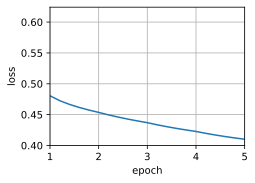

In [30]:
lr, num_epochs = 0.002, 5
train(net, data_iter, lr, num_epochs)

**Applying Word Embeddings** :After training the word2vec model, we can use the cosine similarity of word vectors from
the trained model to find words from the dictionary that are most semantically similar to
an input word.

In [31]:
def get_similar_tokens(query_token, k, embed):
    W = embed.weight.data
    x = W[vocab[query_token]]
    # Compute the cosine similarity. Add 1e-9 for numerical stability
    cos = torch.mv(W, x) / torch.sqrt(torch.sum(W * W, dim=1) *
                                      torch.sum(x * x) + 1e-9)
    topk = torch.topk(cos, k=k+1)[1].cpu().numpy().astype('int32')
    for i in topk[1:]: # Remove the input words
        print(f'cosine sim={float(cos[i]):.3f}: {vocab.to_tokens(i)}')
get_similar_tokens('chip', 3, net[0])

cosine sim=0.719: intel
cosine sim=0.676: microprocessor
cosine sim=0.673: drives


### Exercise 1: Finding semantically similar words

To evaluate the learned word embeddings, I tested the model with different input words using the `get_similar_tokens()` function.

I selected the following words:

- `computer`
- `software`
- `market`
- `good`
- `chip`

The function calculates cosine similarity between the embedding of the query word and the embeddings of all words in the vocabulary. It then returns the top three most similar words.

**Hyperparameter tuning:**

To investigate the impact of hyperparameters on embedding quality, I propose experimenting with:

| Hyperparameter | Initial value | Values to test |
|---|---:|---|
| Embedding dimension | 100 | 50, 200 |
| Learning rate | 0.002 | 0.001, 0.003 |
| Number of epochs | 5 | 10, 20 |
| Number of negative samples | 5 | 3, 10 |
| Maximum window size | 5 | 2, 8 |

The results can be compared by examining the nearest words returned for each query and the training loss.

In [65]:
test_words = ['computer', 'software', 'market', 'good', 'chip']

for word in test_words:
    print(f'\nSimilar words to "{word}":')
    get_similar_tokens(word, 3, net[0])


Similar words to "computer":
cosine sim=0.649: desktop
cosine sim=0.589: digital
cosine sim=0.582: intel

Similar words to "software":
cosine sim=0.687: hardware
cosine sim=0.638: computerized
cosine sim=0.636: disks

Similar words to "market":
cosine sim=0.538: plunge
cosine sim=0.514: fueled
cosine sim=0.514: slump

Similar words to "good":
cosine sim=0.572: better
cosine sim=0.547: fairly
cosine sim=0.513: technicians

Similar words to "chip":
cosine sim=0.719: intel
cosine sim=0.676: microprocessor
cosine sim=0.673: drives


### Exercise 2: Dynamic sampling of context and noise words

In the original implementation, context words and negative samples are generated before the training process and remain fixed throughout all training epochs.

An alternative approach is to generate context words and negative samples dynamically for each minibatch during training.

This approach offers several advantages:

1. **Training diversity:** The same center word can be associated with different context words across epochs.
2. **More negative examples:** The model encounters different noise words, providing a wider range of negative training examples.
3. **Reduced sampling bias:** The model is not restricted to a single fixed set of context and negative samples.
4. **Better generalization:** Exposure to different training examples may help the model learn more robust embeddings.

However, dynamic sampling introduces additional computational overhead because samples must be generated during training.

**Implementation:** The next step is to modify the data-loading and training pipeline to generate context and negative samples dynamically for each minibatch.

1. Dynamic Dataset
Instead of storing precomputed contexts and negatives, this Dataset stores the corpus and generates new samples whenever an example is retrieved.

In [66]:
import torch
import random
from torch.utils.data import Dataset, DataLoader

class DynamicPTBDataset(Dataset):

    def __init__(self, corpus, vocab, counter,
                 max_window_size, num_noise_words):

        self.corpus = corpus
        self.vocab = vocab
        self.counter = counter
        self.max_window_size = max_window_size
        self.num_noise_words = num_noise_words

        # Sampling weights for negative sampling
        sampling_weights = [
            counter[vocab.to_tokens(i)] ** 0.75
            for i in range(1, len(vocab))
        ]

        self.generator = RandomGenerator(sampling_weights)

        # Flatten corpus into center-word positions
        self.centers = [
            (sentence_idx, word_idx)
            for sentence_idx, sentence in enumerate(corpus)
            if len(sentence) >= 2
            for word_idx in range(len(sentence))
        ]

    def __len__(self):
        return len(self.centers)

    def __getitem__(self, index):

        sentence_idx, word_idx = self.centers[index]
        sentence = self.corpus[sentence_idx]

        center = sentence[word_idx]

        # Generate a new random context window
        window_size = random.randint(1, self.max_window_size)

        indices = list(range(
            max(0, word_idx - window_size),
            min(len(sentence), word_idx + window_size + 1)
        ))

        indices.remove(word_idx)

        context = [sentence[i] for i in indices]

        # Generate new negative samples
        negatives = []

        while len(negatives) < len(context) * self.num_noise_words:

            neg = self.generator.draw()

            if neg not in context:
                negatives.append(neg)

        return center, context, negatives

2. Create the DataLoader
We reuse your original batchify() function.

In [68]:
def load_data_ptb_dynamic(batch_size, max_window_size,
                          num_noise_words):

    dataset = DynamicPTBDataset(
        corpus,
        vocab,
        counter,
        max_window_size,
        num_noise_words
    )

    data_iter = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True,
        collate_fn=batchify,
        num_workers=0
    )

    return data_iter

In [69]:
batch_size = 512
max_window_size = 5
num_noise_words = 5

dynamic_data_iter = load_data_ptb_dynamic(
    batch_size,
    max_window_size,
    num_noise_words
)

4. Verify that sampling changes
Before training, let's check whether the same example produces different samples.

In [70]:
dataset = dynamic_data_iter.dataset

# Find an example with index 0
sample1 = dataset[0]
sample2 = dataset[0]

print("First sampling:")
print("Center:", vocab.to_tokens(sample1[0]))
print("Context:", vocab.to_tokens(sample1[1]))
print("Negatives:", vocab.to_tokens(sample1[2]))

print("\nSecond sampling:")
print("Center:", vocab.to_tokens(sample2[0]))
print("Context:", vocab.to_tokens(sample2[1]))
print("Negatives:", vocab.to_tokens(sample2[2]))

First sampling:
Center: join
Context: ['director', 'nov.']
Negatives: ['harder', 'news', 'presence', 'cds', 'compared', 'hotel', 'ford', 'reasonable', 'worry', 'a']

Second sampling:
Center: join
Context: ['director', 'nov.']
Negatives: ['a', 'city', 'love', 'three', 'times', 'privately', 'factories', 'city', 'discounted', 'fall']


5. Train the dynamic Word2Vec model
Your original train() function can be reused without changing its logic.

However, initialize a fresh model so that we can compare it fairly with the original model.

loss 0.417, 66188.4 tokens/sec on cuda:0


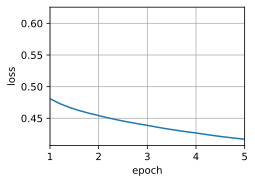

In [71]:
import torch.nn as nn

embed_size = 100

net_dynamic = nn.Sequential(
    nn.Embedding(
        num_embeddings=len(vocab),
        embedding_dim=embed_size
    ),
    nn.Embedding(
        num_embeddings=len(vocab),
        embedding_dim=embed_size
    )
)

lr = 0.002
num_epochs = 5

train(
    net_dynamic,
    dynamic_data_iter,
    lr,
    num_epochs
)

6. Evaluate the dynamic model
Use your existing similarity function, but pass the dynamic model's center embedding:

In [72]:
test_words = [
    'chip',
    'computer',
    'software',
    'market',
    'good'
]

for word in test_words:
    print(f'\nSimilar words to "{word}":')
    get_similar_tokens(word, 3, net_dynamic[0])


Similar words to "chip":
cosine sim=0.814: intel
cosine sim=0.810: microprocessor
cosine sim=0.761: desktop

Similar words to "computer":
cosine sim=0.743: microprocessor
cosine sim=0.736: computers
cosine sim=0.730: chip

Similar words to "software":
cosine sim=0.793: hardware
cosine sim=0.772: microprocessor
cosine sim=0.747: workstations

Similar words to "market":
cosine sim=0.560: bearish
cosine sim=0.553: strengthening
cosine sim=0.550: equities

Similar words to "good":
cosine sim=0.627: eat
cosine sim=0.616: pretty
cosine sim=0.604: funny


7. Compare original and dynamic Word2Vec

In [73]:
test_words = ['chip', 'computer', 'software', 'market']

for word in test_words:

    print("\n" + "=" * 50)
    print("Word:", word)

    print("\nOriginal Word2Vec:")
    get_similar_tokens(word, 3, net[0])

    print("\nDynamic Word2Vec:")
    get_similar_tokens(word, 3, net_dynamic[0])


Word: chip

Original Word2Vec:
cosine sim=0.719: intel
cosine sim=0.676: microprocessor
cosine sim=0.673: drives

Dynamic Word2Vec:
cosine sim=0.814: intel
cosine sim=0.810: microprocessor
cosine sim=0.761: desktop

Word: computer

Original Word2Vec:
cosine sim=0.649: desktop
cosine sim=0.589: digital
cosine sim=0.582: intel

Dynamic Word2Vec:
cosine sim=0.743: microprocessor
cosine sim=0.736: computers
cosine sim=0.730: chip

Word: software

Original Word2Vec:
cosine sim=0.687: hardware
cosine sim=0.638: computerized
cosine sim=0.636: disks

Dynamic Word2Vec:
cosine sim=0.793: hardware
cosine sim=0.772: microprocessor
cosine sim=0.747: workstations

Word: market

Original Word2Vec:
cosine sim=0.538: plunge
cosine sim=0.514: fueled
cosine sim=0.514: slump

Dynamic Word2Vec:
cosine sim=0.560: bearish
cosine sim=0.553: strengthening
cosine sim=0.550: equities


### Exercise 2: Dynamic sampling implementation

I implemented a dynamic sampling strategy for Skip-gram with negative sampling.

Unlike the original implementation, which generates context words and negative samples before training, the modified Dataset generates new samples whenever a training example is retrieved.

The context window is randomly selected for each retrieval, and negative words are sampled using the frequency-based distribution raised to the power of 0.75.

This approach allows the same center word to be associated with different positive context words and negative samples across training epochs.

The main advantages are increased training diversity, exposure to a wider range of negative examples, and reduced dependence on a fixed set of randomly generated samples.

The dynamic implementation can be compared with the original model using training loss and cosine similarity between word embeddings.